# M03 — Admisión magnética y retención espacial

**Pregunta:** ¿Cómo evita la partición espacial M03 la fuga entre líneas sin afirmar que hay una inversión?

**Nivel 2 · Prerrequisitos: notebook de fundamentos; lectura: 25 minutos.**


## Objetivos

Ejecute el parser y planificador geométrico estrictos del producto sobre el fixture protocolario original de 288 filas. No contiene respuesta magnética medida. Un control sintético analítico prueba la continuación armónica. Otro experimento CSV controlado ejecuta el procesador M03 de líneas de vuelo, incluido QC de altura, cruces con líneas de amarre, puntaje por líneas completas y grilla soportada. Ninguno constituye evidencia de campo.


## Preparación

Use el entorno pipeline Python 3.12 revisado. Esta notebook no instala nada. Importa directamente el parser, el planificador, el procesador M03 de líneas magnéticas y la implementación de continuación del repositorio. El CSV generado se escribe solo bajo `CAOS_TEMP_ROOT`, raíz temporal externa que usa el ejecutor.


In [1]:
import runpy, sys
from pathlib import Path

root = Path.cwd().parents[2]
sys.path.insert(0, str(root / "data-pipeline"))
from magnetic_survey_json import parse_request
from magnetic_survey import plan_geometry

support = runpy.run_path(str(root / "tests/data/magnetic_survey_support.py"))
# Verifique la ubicación real del código fuente del planificador.
print(Path(__import__("magnetic_survey").__file__).name)


magnetic_survey.py


## Datos

El planificador usa el fixture geométrico original de 288 filas, sin respuesta magnética medida. La continuación genera un campo periódico analítico con verdad conocida. El procesador de líneas usa otro levantamiento sintético de campo total: ocho líneas de vuelo, una línea de amarre que las cruza, ruido pequeño con semilla fija, un sesgo deliberado de amarre y un valor atípico de altura. El adaptador CSV compartido calcula el hash de los bytes de origen. Todos los controles son explícitamente sintéticos.

**Archivos:** `tests/data/magnetic_survey_support.py`, `tests/fixtures/magnetic_survey/generate.py`, `data-pipeline/magnetic_survey.py`, `data-pipeline/magnetic_continuation.py`, `data-pipeline/magnetic_processing.py`, `docs/design/features/m03-flightline-processing/requirements.md`.


## Método

El planificador fija ENU en metros, grupos de fuente/vuelo, bloques espaciales deterministas, reserva externa y pliegues con buffer. Filas del mismo grupo o bloque permanecen juntas; se revisan rango y cobertura antes de materializar la verosimilitud. Esto controla la filtración espacial, pero no corrige variación diurna, IGRF, altura ni grillas del proveedor.

El procesador de líneas separado exige un mapa CSV explícito uno a uno y declaraciones de fuente/marco. Marca valores atípicos robustos de altura sin cambiar las observaciones, interpola valores en cruces geométricos vuelo/amarre sin nivelar, retiene un bloque contiguo de líneas completas, puntúa solo predicciones retenidas soportadas y construye la grilla con valores de vuelo de ajuste usando SciPy `LinearNDInterpolator`. Las celdas fuera de la envolvente convexa Delaunay quedan enmascaradas. El espaciamiento muestrea el mismo interpolador y no cambia el puntaje retenido. No se afirma corrección, equivalencia con proveedor ni modelo inverso.

El fixture del planificador entrega coordenadas este/norte/arriba en metros, IDs de grupo de vuelo, ancho de bloque explícito y buffer de 200 m. El planificador une filas que comparten grupo de vuelo o bloque espacial; las conexiones transitivas forman unidades indivisibles. Ordena esas unidades determinísticamente, retiene cerca de una quinta parte para evaluación externa y crea pliegues de desarrollo. En cada pliegue excluye del ajuste las filas dentro de b de filas de validación o reserva externa: retiene i solo si minⱼ∈H ‖xᵢ−xⱼ‖₂>b. Es una regla de control de filtración, no una corrección magnética. La partición espacial train/test de Verde es la referencia relacionada [API](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html).

El planificador también verifica rango geométrico: para coordenadas horizontales centradas X=[1,e−ē,n−n̄] se exige rank(X)=3 para evitar que el diseño colapse a una línea. Esto evalúa soporte de coordenadas, no identificabilidad de propiedades del campo. El fixture contiene doce líneas y 288 posiciones, sin respuesta magnética. El mapa muestra pertenencia exacta al primer pliegue, incluidos los buffers. La elegibilidad actual retiene aceptación online/de método completo porque siguen pendientes licencia, procedencia, verosimilitud validada y vínculo con el optimizador.

Ejecute el método del producto sobre el control declarado.


In [2]:
raw = support["encode"](support["request"]())
# Valide los bytes serializados exactos y calcule el sello geométrico determinista.
handle = parse_request(raw)
plan = plan_geometry(handle)
print(
    {
        "esquema": handle.metadata()["schema"],
        "hash_particion": plan["partition"]["sha256"],
        "filas_outer": len(plan["partition"]["outer_rows"]["data"]),
        "pliegues": len(plan["partition"]["folds"]),
        "inversion_ejecutada": False,
    }
)


{'esquema': 'magnetic-survey-inversion-1', 'hash_particion': '18c36c658217ee39da1c3cdda336389f4b0a0d8115c928b6707a114e1753e12e', 'filas_outer': 72, 'pliegues': 3, 'inversion_ejecutada': False}


La partición espacial bloqueada es preferible a dividir puntos al azar en líneas correlacionadas. Verde documenta partición espacial train/test ([referencia API](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html)); el producto además sella grupos y aplica buffer a filas retenidas. Los módulos actuales ejecutan parser/geometría: no corrección magnética, núcleo ni optimizador.
Use directamente los índices de filas devueltos por el planificador. La figura cartografía el diseño de partición con ejes físicos en metros; sus categorías codifican la política de ajuste/holdout, nunca amplitud magnética.


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Graficar índices exactos del planificador sobre geometría local creada; los colores solo codifican partición.
meta = handle.metadata()
xyz = np.asarray(meta["geometry"]["receivers_m"]["data"], dtype=float).reshape(-1, 3)
externo = np.asarray(plan["partition"]["outer_rows"]["data"], dtype=int)
f = plan["partition"]["folds"][0]
ajuste = np.asarray(f["fit_rows"]["data"], dtype=int)
validacion = np.asarray(f["validation_rows"]["data"], dtype=int)
buffer = np.asarray(f["buffered_rows"]["data"], dtype=int)
desarrollo = set(plan["partition"]["development_rows"]["data"])
assert not (set(externo) & desarrollo) and not (
    set(ajuste) & set(validacion) or set(ajuste) & set(buffer) or set(validacion) & set(buffer)
)


### Graficar índices de partición espacial

Los grupos de filas verificados se ubican en las posiciones reales de receptor; el mapa muestra dónde caen ajuste, validación, buffer y reserva exterior en el levantamiento.

{'externo': 72, 'ajuste': 144, 'validacion': 72, 'buffer': 0, 'método_completo_aceptado': False, 'fuente_de_campo_verificada': False, 'verdad_geológica_conocida': False, 'admitido_en_línea': False}


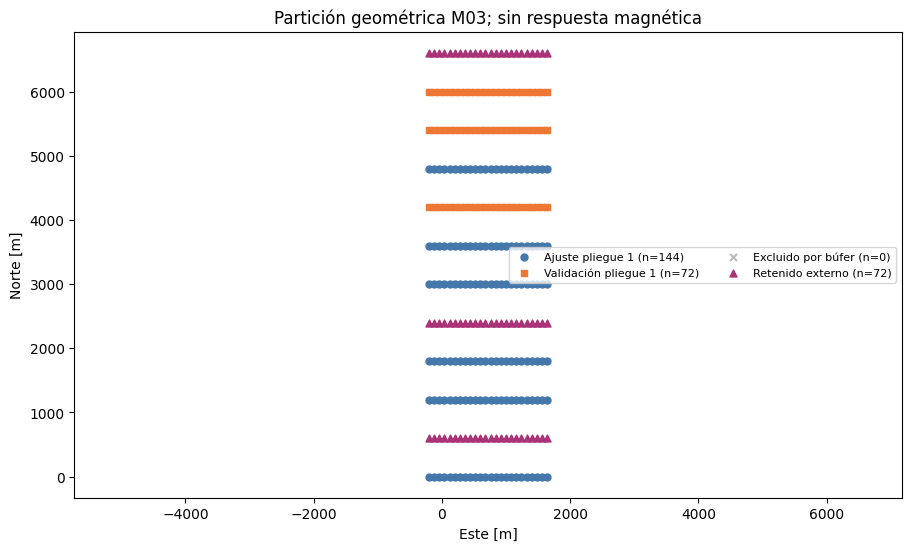

In [4]:
# Graficar índices de partición espacial.
fig, ax = plt.subplots(figsize=(9, 5.4), constrained_layout=True)
for ids, etiqueta, color, marcador in [
    (ajuste, "Ajuste pliegue 1", "#4477aa", "o"),
    (validacion, "Validación pliegue 1", "#ee7733", "s"),
    (buffer, "Excluido por búfer", "#bbbbbb", "x"),
    (externo, "Retenido externo", "#aa3377", "^"),
]:
    ax.scatter(xyz[ids, 0], xyz[ids, 1], label=f"{etiqueta} (n={len(ids)})", c=color, marker=marcador, s=25)
ax.set(xlabel="Este [m]", ylabel="Norte [m]", title="Partición geométrica M03; sin respuesta magnética")
ax.set_aspect("equal", adjustable="datalim")
ax.legend(ncol=2, fontsize=8)
print(
    {
        "externo": len(externo),
        'ajuste': len(ajuste),
        "validacion": len(validacion),
        "buffer": len(buffer),
        "método_completo_aceptado": plan["claims"]["full_method_accepted"],
        "fuente_de_campo_verificada": plan["claims"]["field_source_verified"],
        "verdad_geológica_conocida": plan["claims"]["geology_truth_known"],
        "admitido_en_línea": plan["claims"]["online_admitted"],
    }
)
plt.show()


### Inspección visual de la geometría de receptores codificada

El mapa muestra coordenadas de receptores y grupos protocolarios antes de interpretar el planificador. Puede revelar un orden de coordenadas incorrecto o un bloque mal ubicado, pero todas las respuestas son cero por construcción. La figura solo comprueba geometría y serialización; no muestra anomalías magnéticas, calidad de cobertura ni separación predictiva.


In [5]:
# Vuelva a analizar los mismos bytes como paso independiente.
handle_repeat = parse_request(raw)
print(handle_repeat.metadata()["observations"]["values_sha256"])


71c642b31e5890a15ef92f3cbeba34edfb6e2e9f63079ecbda13a89d426f7d8b


Recalcule el plan geométrico sellado y compruebe determinismo.

In [6]:
# Recalcule el plan geométrico sellado y compruebe determinismo.
plan_repeat = plan_geometry(handle_repeat)
print(plan_repeat["partition"]["sha256"] == plan["partition"]["sha256"])


True


Calcule el hash canónico de identidad de partición devuelta por el pipeline.

In [7]:
# Calcule el hash canónico de identidad de partición devuelta por el pipeline.
from magnetic_survey_json import digest

print(digest(plan["partition"]))


e9393ca2a06106e09bc26583f7d26d23c784788df0beecf3da3e34da1b61883e


Una solicitud malformada es control negativo, no un sondeo alternativo reducido.

In [8]:
# Una solicitud malformada es control negativo, no un sondeo alternativo reducido.
from magnetic_survey_json import InputError

try:
    parse_request(raw + b"x")
except InputError as error:
    print("refused:", error.code)


refused: type


El primer mapa muestra las funciones asignadas por el planificador en sus coordenadas este/norte reales. Este gráfico complementario agrega los registros sellados de cada pliegue para mostrar cómo la reserva externa, la validación y las exclusiones por búfer reducen el conjunto de ajuste. Son conteos de geometría de partición; el fixture no contiene respuesta magnética y no informa desempeño predictivo ni cobertura de terreno.

Compare los conteos retenidos de ajuste, validación y búfer entre los pliegues planificados.

{'Pliegue 1': {'ajuste': 144, 'validación': 72, 'búfer': 0}, 'Pliegue 2': {'ajuste': 144, 'validación': 72, 'búfer': 0}, 'Pliegue 3': {'ajuste': 144, 'validación': 72, 'búfer': 0}}


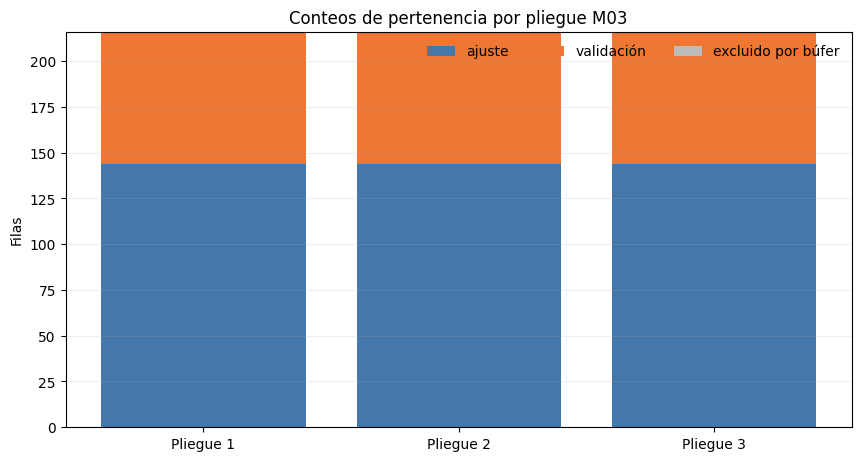

In [9]:
# Agregue los índices exactos del planificador para cada pliegue predefinido.
import numpy as np
import matplotlib.pyplot as plt

folds = plan["partition"]["folds"]
labels = [f"Pliegue {i + 1}" for i in range(len(folds))]
fit_n = [len(f["fit_rows"]["data"]) for f in folds]
validation_n = [len(f["validation_rows"]["data"]) for f in folds]
buffer_n = [len(f["buffered_rows"]["data"]) for f in folds]
x = np.arange(len(folds))
fig, ax = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
ax.bar(x, fit_n, label="ajuste", color="#4477aa")
ax.bar(x, validation_n, bottom=fit_n, label="validación", color="#ee7733")
bottom = np.asarray(fit_n) + np.asarray(validation_n)
ax.bar(x, buffer_n, bottom=bottom, label="excluido por búfer", color="#bbbbbb")
ax.set(xticks=x, xticklabels=labels, ylabel="Filas", title="Conteos de pertenencia por pliegue M03")
ax.legend(frameon=False, ncol=3)
ax.grid(axis="y", alpha=0.2)
print(
    {etiqueta: {"ajuste": a, "validación": b, "búfer": c} for etiqueta, a, b, c in zip(labels, fit_n, validation_n, buffer_n)}
)
plt.show()


Las barras son conteos directos de los índices serializados del planificador, no una segunda implementación de partición. Un búfer amplio puede reducir mucho las filas de ajuste, mientras los conteos de validación permanecen fijados por el pliegue sellado; el compromiso queda visible antes de considerar una respuesta o inversión. La reserva externa no aparece en estas categorías de desarrollo. El gráfico permite auditar el soporte geométrico disponible, pero no demuestra generalización de un estimador magnético futuro.

### Continuación hacia arriba: experimento espectral controlado

Para un campo potencial armónico en un semiespacio libre de fuentes, cada modo de Fourier horizontal con magnitud de número de onda \(k\) decae con la altura como \(e^{-kh}\). El experimento combina un modo conocido con un plano regional afín, lo continúa 500 m y compara ambas predicciones con la solución analítica. El plano afín se conserva porque su laplaciano es cero. La FFT usa extensión periódica; al elegir una ventana de levantamiento real hay que considerar el diagnóstico de discontinuidad en los bordes.

altura=500 m; atenuación del modo=0.014022; error analítico máximo=6.548e-11 nT
razón de salto en bordes FFT: 0.8228287049076314


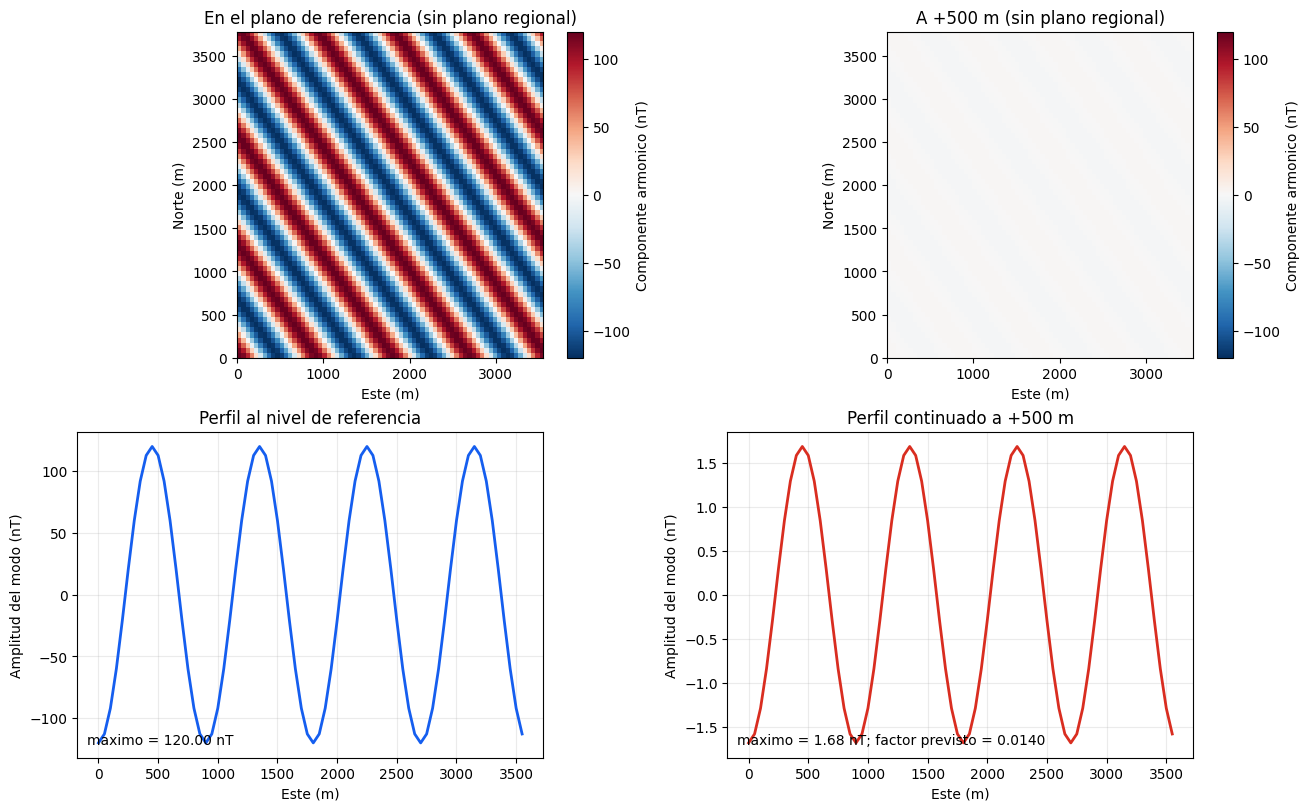

In [10]:
# Es un control numérico con verdad conocida, no una grilla medida de Charleston.
import numpy as np
import matplotlib.pyplot as plt
from magnetic_continuation import upward_continue

ny, nx = 64, 72
dx, dy, height_m = 50.0, 60.0, 500.0
easting = np.arange(nx) * dx
northing = np.arange(ny) * dy
xx, yy = np.meshgrid(easting, northing, indexing="xy")
mode_x, mode_y, amplitude = 4, 3, 120.0
phase = 2 * np.pi * mode_x * xx / (nx * dx) + 2 * np.pi * mode_y * yy / (ny * dy)
regional = 50000.0 + 0.012 * xx - 0.018 * yy
observed = regional + amplitude * np.cos(phase)
continued_record = upward_continue(
    observed, spacing_easting_m=dx, spacing_northing_m=dy, height_m=height_m,
    support_mask=np.ones_like(observed, dtype=bool),
)
radial_k = np.hypot(2 * np.pi * mode_x / (nx * dx), 2 * np.pi * mode_y / (ny * dy))
attenuation = np.exp(-radial_k * height_m)
analytic = regional + amplitude * attenuation * np.cos(phase)
continued = np.asarray(continued_record["values"])
max_error = float(np.max(np.abs(continued - analytic)))
print(f"altura={height_m:.0f} m; atenuación del modo={attenuation:.6f}; error analítico máximo={max_error:.3e} nT")
print("razón de salto en bordes FFT:", continued_record["edge_periodicity_diagnostic"]["maximum_seam_jump_over_grid_std"])
assert max_error < 1e-8
assert np.max(np.abs(continued - regional)) < np.max(np.abs(observed - regional))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
mode_observed = observed - regional
mode_continued = continued - regional
for ax, field, title in zip(axes[0], (mode_observed, mode_continued),
                            ("En el plano de referencia (sin plano regional)", f"A +{height_m:.0f} m (sin plano regional)")):
    image = ax.imshow(field, origin="lower", extent=[easting[0], easting[-1], northing[0], northing[-1]],
                      cmap="RdBu_r", vmin=-amplitude, vmax=amplitude, aspect="equal")
    ax.set(title=title, xlabel="Este (m)", ylabel="Norte (m)")
    fig.colorbar(image, ax=ax, label="Componente armonico (nT)")
axes[1, 0].plot(easting, mode_observed[ny // 2], color="#155eef", lw=2)
axes[1, 0].set(title="Perfil al nivel de referencia", xlabel="Este (m)", ylabel="Amplitud del modo (nT)")
axes[1, 0].text(.02, .04, f"maximo = {np.max(np.abs(mode_observed[ny // 2])):.2f} nT",
                transform=axes[1, 0].transAxes, fontsize=10)
axes[1, 1].plot(easting, mode_continued[ny // 2], color="#d92d20", lw=2)
axes[1, 1].set(title=f"Perfil continuado a +{height_m:.0f} m", xlabel="Este (m)", ylabel="Amplitud del modo (nT)")
axes[1, 1].text(.02, .04, f"maximo = {np.max(np.abs(mode_continued[ny // 2])):.2f} nT; factor previsto = {attenuation:.4f}",
                transform=axes[1, 1].transAxes, fontsize=10)
for ax in axes[1]: ax.grid(alpha=.25)
plt.show()

El modo discreto pierde el factor previsto \(e^{-kh}\) y el plano regional afín permanece sin cambios. Esto verifica la implementación frente al operador analítico de Fourier para este campo sintético periódico. No valida la grilla de entrada, el tratamiento de bordes, las correcciones del levantamiento, el procesamiento del proveedor ni la interpretación geológica. Para una grilla de usuario, seleccione una ROI rectangular con soporte completo, revise el salto de borde informado y documente cualquier ventana aplicada antes de continuar.

In [11]:
# Las celdas faltantes deben detener el cálculo; rellenarlas en silencio inventaría soporte de campo.
from magnetic_continuation import ContinuationError
mask = np.ones((8, 8), dtype=bool)
mask[0, 0] = False
try:
    upward_continue(np.ones((8, 8)), spacing_easting_m=25, spacing_northing_m=25,
                    height_m=100, support_mask=mask)
except ContinuationError as error:
    print("rechazo esperado:", error)
else:
    raise AssertionError("se aceptaron celdas sin soporte")

rechazo esperado: upward continuation requires a complete true support mask


Resultado esperado: `upward continuation requires a complete true support mask`.

### Ejecutar el procesador de CSV de líneas de vuelo

Esta sección complementa el planificador geométrico con el flujo CSV M03 real del producto. El archivo fuente sintético se conserva fuera del repositorio bajo `CAOS_TEMP_ROOT`.


In [12]:
# Cargar el flujo M03 compartido y las herramientas de visualización científica.
import csv, hashlib, json, os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / "data-pipeline"))
from magnetic_processing import read_csv, process
source_file = Path(os.environ["CAOS_TEMP_ROOT"]) / "m03-flightline-controlled.csv"
print("processor:", Path(sys.modules["magnetic_processing"].__file__).resolve().relative_to(root))
print("temporary CSV:", source_file.name)


processor: data-pipeline\magnetic_processing.py
temporary CSV: m03-flightline-controlled.csv


### Crear un levantamiento controlado

El campo combina un gradiente regional y dos anomalías suaves. Una semilla fija agrega ruido gaussiano de medición de 0,25 nT. Ocho líneas paralelas se separan 100 m; una línea de amarre las cruza en x=525 m, entre muestras. Una altura se eleva deliberadamente a 105 m. El QC debe informar el sesgo de +6 nT de la línea de amarre sin corregirlo. Las coordenadas usan un marco local sintético proyectado en metros.


In [13]:
# Generar un levantamiento determinista con anomalía de altura y sesgo de amarre deliberados.
rng = np.random.default_rng(240518)
def field(x, y):
    return (50000.0 + .012*x - .018*y
        + 18*np.exp(-((x-690)**2/(2*190**2)+(y-335)**2/(2*170**2)))
        - 11*np.exp(-((x-300)**2/(2*135**2)+(y-610)**2/(2*110**2))))
rows = []
for i, y in enumerate(np.arange(0., 800., 100.)):
    line = f"F{i+1:02d}"
    for order, x in enumerate(np.arange(0., 1200.1, 100.)):
        height = 70 + 1.5*np.sin(order/3)
        if line == "F04" and order == 5: height = 105.0
        rows.append({"E_m":x,"N_m":y,"TMI_nT":field(x,y)+rng.normal(0,.25),"line":line,
                     "role":"flight","height_m":height,"order":order})
for order,y in enumerate(np.arange(0.,800.,100.)):
    x=525.
    rows.append({"E_m":x,"N_m":y,"TMI_nT":field(x,y)+6+rng.normal(0,.25),"line":"T01",
                 "role":"tie","height_m":72.,"order":order})
source_file.parent.mkdir(parents=True,exist_ok=True)
with source_file.open("w",newline="",encoding="utf-8") as stream:
    writer=csv.DictWriter(stream,fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
print({"row_count":len(rows),"flight_lines":8,"tie_lines":1,"bytes":source_file.stat().st_size,
       "source_sha256":hashlib.sha256(source_file.read_bytes()).hexdigest()})


{'row_count': 112, 'flight_lines': 8, 'tie_lines': 1, 'bytes': 6742, 'source_sha256': 'b55120642f093b2d1c0463c15bb44c91aa48a6e746559d5568b158310076010c'}


### Ejecutar la implementación compartida del producto

El adaptador CSV calcula el hash de los bytes originales y acepta solo el mapa explícito de siete columnas. El procesador ejecuta geometría y QC robusto de altura, cruces interpolados por segmentos, reserva contigua y determinista de líneas completas, métricas de predicción retenida y una grilla Delaunay lineal por tramos. Los valores de amarre se conservan para QC, pero se excluyen del ajuste. La reserva del 20% y la semilla se fijan antes de inspeccionar resultados.


In [14]:
# Mapear las columnas declaradas y ejecutar las funciones reales del producto.
field_map={"easting":"E_m","northing":"N_m","value":"TMI_nT","line_id":"line","line_role":"role","sensor_height_m":"height_m","sample_order":"order"}
source={"source_id":"synthetic:m03-flightline-controlled-v1","citation":"Notebook-authored analytic control; no external source",
 "rights_decision":"authored synthetic data","processing_state":"synthetic total-field values; deliberate +6 nT tie offset; no corrections",
 "value_unit":"nT","value_quantity":"synthetic total-field anomaly","sensor_height_reference":"above local synthetic ground"}
frame={"crs":"LOCAL:synthetic-projected-metres","coordinates_are_projected":True,"linear_unit":"m"}
settings={"grid_spacing_m":100.,"holdout_fraction":.20,"seed":"m03-bilingual-course-v1"}
request=read_csv(source_file,field_map=field_map,source_metadata=source,frame=frame,settings=settings)
result=process(request,source_hash_verified=True)
score=result["heldout_interpolation"]; qc=result["geometry_qc"]["crossover_interpolation_qc"]
height_flags=[(l["line_id"],l["sensor_height_m"]["qc_outlier_rows"]) for l in result["geometry_qc"]["lines"] if l["sensor_height_m"]["qc_outlier_rows"]]
print(json.dumps({"sha256":result["source"]["sha256"],"fit_lines":result["split"]["fit_line_ids"],
 "heldout_lines":result["split"]["holdout_line_ids"],"heldout_rows":score["heldout_row_count"],
 "supported_rows":score["supported_heldout_row_count"],"coverage":score["coverage_fraction"],
 "MAE_nT":score["mae"],"RMSE_nT":score["rmse"],"height_flags":height_flags,
 "crossover_count":qc["intersection_count"],"crossover_mean_signed_nT":qc["mean_signed_difference"],
 "grid_shape_yx":result["grid"]["shape_yx"],"supported_cells":int(np.asarray(result["grid"]["support_mask"]).sum()),
 "claims":result["claims"]},indent=2))
assert height_flags and qc["intersection_count"] > 0 and score["heldout_row_count"] > 0
assert result["claims"]["corrections_applied"] == [] and not result["claims"]["inverse_model"]


{
  "sha256": "b55120642f093b2d1c0463c15bb44c91aa48a6e746559d5568b158310076010c",
  "fit_lines": [
    "F01",
    "F02",
    "F03",
    "F04",
    "F05",
    "F08"
  ],
  "heldout_lines": [
    "F06",
    "F07"
  ],
  "heldout_rows": 26,
  "supported_rows": 26,
  "coverage": 1.0,
  "MAE_nT": 1.3886361098671982,
  "RMSE_nT": 1.9908756067541955,
  "height_flags": [
    [
      "F04",
      [
        5
      ]
    ]
  ],
  "crossover_count": 8,
  "crossover_mean_signed_nT": -5.9897483283457404,
  "grid_shape_yx": [
    8,
    13
  ],
  "supported_cells": 104,
  "claims": {
    "source_hash_recomputed_from_original_bytes": true,
    "corrections_applied": [],
    "provider_grid_comparison": false,
    "inverse_model": false,
    "scientific_release_accepted": false
  }
}


### Mapear las filas e inspeccionar diferencias en cruces

La vista izquierda ubica las filas exactas de entrada; vuelo y amarre usan símbolos distintos. Un anillo marca la muestra de altura revisada y conserva su valor magnético. La vista derecha grafica diferencias vuelo-menos-amarre interpoladas por segmentos. Su promedio se aproxima a los +6 nT inyectados, con desvíos por ruido e interpolación. Es un diagnóstico, no una corrección automática.


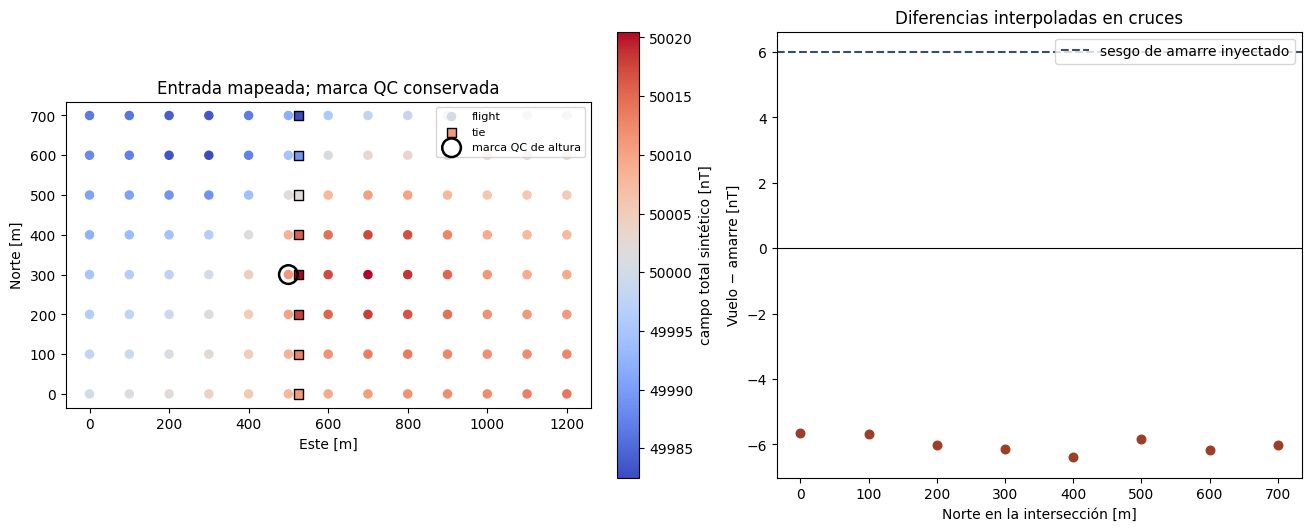

In [15]:
# Graficar geometría de entrada y diagnósticos de cruces del procesador.
flight=[r for r in rows if r["role"]=="flight"]; tie=[r for r in rows if r["role"]=="tie"]
fig,ax=plt.subplots(1,2,figsize=(13,5.2),constrained_layout=True)
sc=ax[0].scatter([r["E_m"] for r in flight],[r["N_m"] for r in flight],c=[r["TMI_nT"] for r in flight],cmap="coolwarm",s=34,label="flight")
ax[0].scatter([r["E_m"] for r in tie],[r["N_m"] for r in tie],c=[r["TMI_nT"] for r in tie],cmap="coolwarm",marker="s",s=44,edgecolor="black",label="tie")
flag=next(r for r in rows if r["line"]=="F04" and r["order"]==5)
ax[0].scatter([flag["E_m"]],[flag["N_m"]],s=180,facecolors="none",edgecolors="black",linewidths=1.8,label="marca QC de altura")
ax[0].set(title="Entrada mapeada; marca QC conservada",xlabel="Este [m]",ylabel="Norte [m]",aspect="equal"); ax[0].legend(fontsize=8); fig.colorbar(sc,ax=ax[0],label="campo total sintético [nT]")
crossings=qc["crossings"]
ax[1].scatter([c["northing_m"] for c in crossings],[c["difference_a_minus_b"] for c in crossings],color="#9b3f28",s=38)
ax[1].axhline(6,color="#344f70",linestyle="--",label="sesgo de amarre inyectado"); ax[1].axhline(0,color="black",lw=.8)
ax[1].set(title="Diferencias interpoladas en cruces",xlabel="Norte en la intersección [m]",ylabel="Vuelo − amarre [nT]"); ax[1].legend()
plt.show()


### Inspeccionar la grilla soportada y las líneas retenidas

La grilla ajusta solo observaciones de vuelo. Las celdas grises tienen máscara de soporte falsa; el cero guardado allí es una codificación, no una medición física. Las cruces naranjas muestran las líneas completas retenidas. Lea cobertura junto con MAE/RMSE: un error bajo en una fracción pequeña con soporte no implica amplia cobertura del levantamiento.


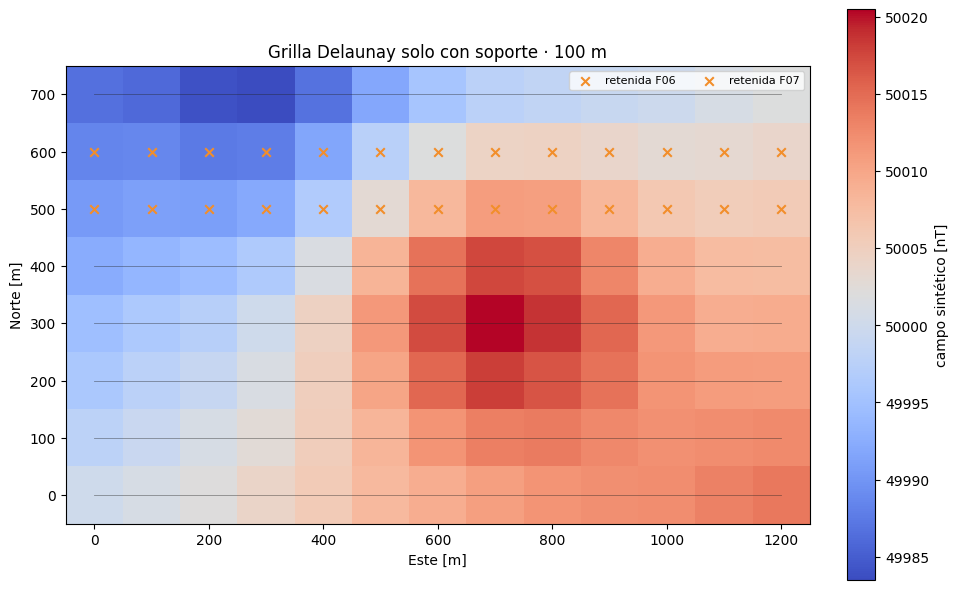

Interpolación retenida: 26/26 supported; coverage=100.0%; MAE=1.389 nT; RMSE=1.991 nT


In [16]:
# Mostrar los valores devueltos solo donde la máscara de soporte del producto es verdadera.
g=result["grid"]; x=np.asarray(g["x_easting_m"]); y=np.asarray(g["y_northing_m"])
values=np.asarray(g["values"],float); mask=np.asarray(g["support_mask"],bool)
fig,ax=plt.subplots(figsize=(9.5,5.8),constrained_layout=True)
mesh=ax.pcolormesh(x,y,np.ma.masked_where(~mask,values),shading="nearest",cmap="coolwarm")
for line_id in result["split"]["fit_line_ids"]:
    line=[r for r in flight if r["line"]==line_id]; ax.plot([r["E_m"] for r in line],[r["N_m"] for r in line],color="#222",lw=.6,alpha=.45)
for line_id in result["split"]["holdout_line_ids"]:
    line=[r for r in flight if r["line"]==line_id]; ax.scatter([r["E_m"] for r in line],[r["N_m"] for r in line],marker="x",color="#f28e2b",s=38,label=f"retenida {line_id}")
ax.set(title="Grilla Delaunay solo con soporte · 100 m",xlabel="Este [m]",ylabel="Norte [m]",aspect="equal"); ax.legend(ncol=2,fontsize=8); fig.colorbar(mesh,ax=ax,label="campo sintético [nT]")
plt.show()
print(f"Interpolación retenida: {score['supported_heldout_row_count']}/{score['heldout_row_count']} supported; coverage={score['coverage_fraction']:.1%}; MAE={score['mae']:.3f} nT; RMSE={score['rmse']:.3f} nT")


### Cambiar espaciamiento: muestreo no es resolución

La ejecución de 200 m usa los mismos bytes CSV, mapa, semilla, reserva e interpolador. Solo cambia el muestreo de la grilla de salida. El puntaje retenido debe ser idéntico porque evalúa el mismo interpolador continuo lineal en coordenadas retenidas. Un raster más denso no agrega información geológica.


In [17]:
# Cambiar espaciamiento manteniendo fijos datos, partición e interpolación.
coarse_settings={**settings,"grid_spacing_m":200.}
coarse_request=read_csv(source_file,field_map=field_map,source_metadata=source,frame=frame,settings=coarse_settings)
coarse=process(coarse_request,source_hash_verified=True); coarse_score=coarse["heldout_interpolation"]
print({"grid_100m":result["grid"]["shape_yx"],"grid_200m":coarse["grid"]["shape_yx"],
 "same_holdout":result["split"]["holdout_line_ids"]==coarse["split"]["holdout_line_ids"],
 "same_RMSE":score["rmse"]==coarse_score["rmse"],"RMSE_100m_nT":score["rmse"],"RMSE_200m_nT":coarse_score["rmse"]})
assert result["split"]["holdout_line_ids"]==coarse["split"]["holdout_line_ids"]
assert score["rmse"]==coarse_score["rmse"] and result["grid"]["shape_yx"]!=coarse["grid"]["shape_yx"]


{'grid_100m': [8, 13], 'grid_200m': [4, 7], 'same_holdout': True, 'same_RMSE': True, 'RMSE_100m_nT': 1.9908756067541955, 'RMSE_200m_nT': 1.9908756067541955}


### Interpretación y límites

The shared implementation parsed the mapped CSV, reported the injected height and crossover conditions, retenida complete flight lines, calculated a support-masked interpolation grid and scored held-out rows. It applied no tie-line levelling or other correction. Coarser grid spacing changed array sampling but left validation metrics unchanged.

Este experimento **no** establece precisión de campo, equivalencia con grilla del proveedor, verdad geológica, correcciones diurna/IGRF/retardo/terreno, modelo inverso magnético ni ejecución segura en navegador. La verdad analítica se conoce solo porque esta lección creó el generador. Los datos reales requieren derechos, CRS/datum, unidades, orden de adquisición e historial de procesamiento documentados, además de validación independiente por fuente.

### Referencias

- Li (2006), *Understanding 3D analytic signal amplitude*, Geophysics 71(2), L13–L16. [doi:10.1190/1.2184367](https://doi.org/10.1190/1.2184367). Context only; no inverse is performed here.
- SciPy [`LinearNDInterpolator`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.LinearNDInterpolator.html): piecewise-linear interpolation on a Qhull Delaunay triangulation.
- Product source: `data-pipeline/magnetic_processing.py`; requirements: `docs/design/features/m03-flightline-processing/requirements.md`.


## Resultados

El planificador verifica esquema y partición espacial, no una predicción medida. La continuación ejecuta el operador Fourier del producto ante verdad sintética cerrada. El control de líneas pasa un CSV sintético por el adaptador y procesador reales: informa la marca de altura y discrepancia de amarre inyectadas, calcula una reserva determinista por línea completa, evalúa cobertura/error y entrega una grilla con máscara de soporte. Espaciar más la grilla conserva los puntajes retenidos. Si falla, conserve el rechazo; no reduzca el buffer ni invente mediciones de campo.

El planificador une grupos de vuelo y bloques espaciales compartidos para sellar una reserva externa y pliegues con buffer. Como opera sobre metadatos, su salida no es un puntaje de predicción. La continuación usa un campo periódico exacto y un plano regional afín. El procesamiento de líneas es un levantamiento analítico propio; ninguno de estos resultados entrega precisión sobre datos de proveedor.


## Resumen

La reserva externa de 72 filas y los pliegues con buffer se calculan para un fixture geométrico propio. Un control Fourier verifica la continuación de un modo armónico y conserva el plano regional. El procesador M03 compartido también procesa un CSV sintético completo: hash de origen, QC de altura y cruces, retención de líneas completas y grilla con máscara; cambiar espaciamiento altera el arreglo, no el puntaje retenido. No se incluye un levantamiento medido del proveedor; correcciones, nivelación, comparación con grillas de proveedor, validez de campo e inversión del subsuelo quedan fuera de esta evidencia.


## Referencias

- Blakely, R. J. (1995), *Potential Theory in Gravity and Magnetic Applications*, Cambridge University Press, capítulo 12. [Referencia del libro](https://www.cambridge.org/core/books/potential-theory-in-gravity-and-magnetic-applications/).
- [Partición espacial de entrenamiento y prueba de Verde](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html).
